Compare clinical baselines, budget controls and Delphi panels using paired case-level scores.


In [1]:
import os, sys, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def _build_data_tools():
    import json
    import os
    import re
    import unicodedata
    import warnings
    import numpy as np
    import pandas as pd
    from scipy import stats
    warnings.filterwarnings('ignore')

    def path_join(*parts):
        return os.path.normpath(os.path.join(*parts))

    def normalize_newlines(frame):
        for column in frame.select_dtypes(include=['object', 'string']).columns:
            frame[column] = frame[column].map(lambda value: value.replace('\r\n', '\n').replace('\r', '\n') if isinstance(value, str) else value)
        return frame
    from pathlib import Path
    _start = Path.cwd().resolve()
    _repo = next((p for p in (_start, *_start.parents) if (p / 'experiments/clinical_protocols').is_dir() and (p / 'data').is_dir()), None)
    if _repo is None:
        raise FileNotFoundError('Run the notebook from inside the repository.')
    if os.name == 'nt' and (not str(_repo).startswith(chr(92) * 2 + '?' + chr(92))):
        _repo = Path(chr(92) * 2 + '?' + chr(92) + str(_repo))
    GOLD = str(_repo)
    PAPER = str(_repo / 'results/clinical_evaluation')
    HERE = str(_repo / 'analyses/clinical_evaluation')
    ALPHA = GOLD
    RESEARCH = GOLD
    TABLES = path_join(PAPER, 'tables')
    FIGURES = path_join(PAPER, 'figures')
    os.makedirs(TABLES, exist_ok=True)
    os.makedirs(FIGURES, exist_ok=True)
    DATASET = str(_repo / 'data' / 'limfmed_dataset_gold.csv')
    PBASE = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_complete'
    PBASE_NON = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gpt120_organizer_truncated'
    ORG_DS = 'experiments/clinical_protocols/delphi_panels/heterogeneous_deepseek_organizer_complete'
    ORG_QWEN = 'experiments/clinical_protocols/delphi_panels/heterogeneous_qwen_organizer_complete'
    ORG_GEM = 'experiments/clinical_protocols/delphi_panels/heterogeneous_gemini_external_organizer'
    PWEAK = 'experiments/clinical_protocols/delphi_panels/panel_qwen_organizer_gemini_deepseek_pro'
    PMIXED = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_gemini_glm'
    PSTRONG = 'experiments/clinical_protocols/delphi_panels/panel_deepseek_organizer_glm_gpt120'
    HOMOG = {'gpt': 'experiments/homogeneous_panels/three_gpt_members', 'qwen': 'experiments/homogeneous_panels/three_qwen_members', 'deepseekv4': 'experiments/homogeneous_panels/three_deepseekv4_members_complete', 'gemini': 'experiments/homogeneous_panels/three_gemini_members'}
    FIX_PBASE = 'experiments/fixed_length_controls/delphi_panels/internal_panel_variants/standard_protocol/heterogeneous_gpt120_organizer'
    SINGLES = ['gpt', 'qwen', 'deepseekv4', 'deepseekv4pro', 'gemini', 'glm', 'kimi']
    MODEL_NAME = {'gpt': 'gpt-oss-120b', 'qwen': 'qwen3-235b-a22b', 'deepseekv4': 'deepseek-v4-flash', 'deepseekv4pro': 'deepseek-v4-pro', 'gemini': 'gemini-3.7-flash', 'glm': 'glm-5.2', 'kimi': 'kimi'}
    PANELS = {'P-base': (PBASE, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gpt', True), 'P-base/org-ds': (ORG_DS, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'deepseekv4', True), 'P-base/org-qwen': (ORG_QWEN, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'qwen', True), 'P-base/org-gemini': (ORG_GEM, 'delphi_base_{d}_judge.csv', ['gpt', 'qwen', 'deepseekv4'], 'gemini', False), 'P-weak': (PWEAK, 'delphi_pweak_{d}_judge.csv', ['qwen', 'gemini', 'deepseekv4pro'], 'qwen', True), 'P-mixed': (PMIXED, 'delphi_pmixed_{d}_judge.csv', ['deepseekv4', 'gemini', 'glm'], 'deepseekv4', True), 'P-strong': (PSTRONG, 'delphi_pstrong_{d}_judge.csv', ['deepseekv4', 'glm', 'gpt'], 'deepseekv4', True), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_{d}_judge.csv', ['gpt'] * 3, 'gpt', True), 'homog qwen': (HOMOG['qwen'], 'delphi_homog_qwen_{d}_judge.csv', ['qwen'] * 3, 'qwen', True), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_{d}_judge.csv', ['deepseekv4'] * 3, 'deepseekv4', True), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_{d}_judge.csv', ['gemini'] * 3, 'gemini', True)}
    HETERO = ['P-base', 'P-weak', 'P-mixed', 'P-strong']
    HOMOGS = ['homog gpt', 'homog qwen', 'homog deepseekv4', 'homog gemini']
    ORGANIZER_ARMS = ['P-base', 'P-base/org-ds', 'P-base/org-qwen', 'P-base/org-gemini']
    RAW_RUN = {'P-base': PBASE + '/delphi_noroles.csv', 'P-base/org-ds': ORG_DS + '/delphi_noroles.csv', 'P-base/org-qwen': ORG_QWEN + '/delphi_noroles.csv', 'P-base/org-gemini': ORG_GEM + '/delphi_noroles.csv', 'P-weak': PWEAK + '/delphi_pweak_noroles.csv', 'P-mixed': PMIXED + '/delphi_pmixed_noroles.csv', 'P-strong': PSTRONG + '/delphi_pstrong_noroles.csv', 'homog gpt': HOMOG['gpt'] + '/delphi_homog_gpt_noroles.csv', 'homog qwen': HOMOG['qwen'] + '/delphi_homog_qwen_noroles.csv', 'homog deepseekv4': HOMOG['deepseekv4'] + '/delphi_homog_deepseekv4_noroles.csv', 'homog gemini': HOMOG['gemini'] + '/delphi_homog_gemini_noroles.csv'}
    ROUNDS_EVAL = {'P-base': (PBASE, 'delphi_base_noroles_protocol_r{r}_judge.csv'), 'P-weak': (PWEAK, 'delphi_pweak_noroles_protocol_r{r}_judge.csv'), 'P-mixed': (PMIXED, 'delphi_pmixed_noroles_protocol_r{r}_judge.csv'), 'P-strong': (PSTRONG, 'delphi_pstrong_noroles_protocol_r{r}_judge.csv'), 'homog gpt': (HOMOG['gpt'], 'delphi_homog_gpt_noroles_protocol_r{r}_judge.csv'), 'homog gemini': (HOMOG['gemini'], 'delphi_homog_gemini_noroles_protocol_r{r}_judge.csv'), 'homog deepseekv4': (HOMOG['deepseekv4'], 'delphi_homog_deepseekv4_noroles_protocol_r{r}_judge.csv')}

    def baseline_path(model, design='noroles', variant='nofix'):
        return f"experiments/{('clinical_protocols' if variant == 'nofix' else 'fixed_length_controls')}/single_model_baselines/baseline_{model}/llm_as_judge/baseline_{design}_{model}_judge.csv"

    def panel_path(name, design='noroles'):
        d, f, *_ = PANELS[name]
        return d + '/llm_as_judge/' + f.format(d=design)

    def _abs(rel):
        return rel if os.path.isabs(rel) else path_join(GOLD, rel)

    def read_csv(rel, filter_result=True):
        p = _abs(rel)
        if not os.path.exists(p):
            return None
        d = normalize_newlines(pd.read_csv(p, sep=';', encoding='utf-8-sig', low_memory=False))
        d.columns = [c.lstrip('\ufeff') for c in d.columns]
        if filter_result and 'table_source' in d.columns:
            d = d[d['table_source'].fillna('result_df') == 'result_df']
        return d

    def read_judge(rel):
        d = read_csv(rel)
        if d is None or 'Judge_score' not in d.columns:
            return None
        d = d.dropna(subset=['Judge_score', 'Vignette']).drop_duplicates('Vignette', keep='first')
        d['Judge_score'] = pd.to_numeric(d['Judge_score'], errors='coerce')
        return d.set_index('Vignette')

    def load_main_arms(design='noroles', include_usc=False):
        arms = {}
        for m in SINGLES:
            d = read_judge(baseline_path(m, design))
            if d is not None:
                arms[m] = d
        for name in PANELS:
            d = read_judge(panel_path(name, design))
            if d is not None:
                arms[name] = d
        if include_usc and design == 'noroles':
            for k in (3, 5, 7):
                d = read_judge(f'experiments/token_budget_controls/universal_self_consistency_gpt_seven_samples/llm_as_judge/usc_gpt_sc{k}_judge.csv')
                if d is not None:
                    arms[f'USC@{k} gpt'] = d
        return arms

    def score(arms, name):
        return arms[name]['Judge_score'].astype(float)

    def dataset():
        d = normalize_newlines(pd.read_csv(DATASET, sep=None, engine='python'))
        return d

    def protocol_text(d):
        for c in ('winner_protocol', 'baseline_protocol_anonymous', 'baseline_protocol'):
            if c in d.columns:
                return d[c].astype(str)
        raise KeyError('no protocol column')

    def strip_author(text):
        if not isinstance(text, str):
            return ''
        return re.split('(?im)^\\s*Protocol Author\\s*:', text, maxsplit=1)[0].rstrip()

    def n_words(text):
        return len(re.findall('\\S+', strip_author(text))) if isinstance(text, str) else np.nan

    def items(d):
        rows = []
        for v, s in d['judge_details'].dropna().items():
            try:
                arr = json.loads(s)
            except Exception:
                continue
            for it in arr:
                ax = next((t.split(':', 1)[1] for t in it.get('tags') or [] if isinstance(t, str) and t.startswith('axis:')), None)
                rows.append((v, int(it['id']), int(it.get('points', 0) or 0), ax, bool(it.get('met'))))
        return pd.DataFrame(rows, columns=['Vignette', 'cid', 'points', 'axis', 'met'])

    def item_matrix(arms, names, positive_only=True):
        frames = []
        for n in names:
            it = items(arms[n]).set_index(['Vignette', 'cid'])
            frames.append(it['met'].astype(int).rename(n))
            meta = it[['points', 'axis']]
        m = pd.concat(frames, axis=1, join='inner')
        m = m.join(meta, how='left')
        if positive_only:
            m = m[m['points'] > 0]
        return m
    ORD = {'SELF': 0, 'NONEMERG': 1, 'EMERG': 2}
    GT = {'Self-care appropriate': 'SELF', 'Requires non-emergent care': 'NONEMERG', 'Requires emergent care': 'EMERG'}
    _DASH = dict.fromkeys(map(ord, '‐‑‒–—―−\xad'), '-')

    def norm_label(x):
        if not isinstance(x, str) or not x.strip():
            return None
        x = x.strip()
        if x in GT:
            return GT[x]
        s = unicodedata.normalize('NFKC', x).translate(_DASH).lower()
        s = re.sub('\\s+', ' ', re.sub('[^a-z\\- ]', ' ', s)).strip()
        for k, v in (('requires emergent care', 'EMERG'), ('requires non-emergent care', 'NONEMERG'), ('self-care appropriate', 'SELF')):
            if k in s:
                return v
        if 'non-emergent' in s or 'non emergent' in s:
            return 'NONEMERG'
        if 'emergent' in s or 'emergency' in s:
            return 'EMERG'
        if 'self' in s:
            return 'SELF'
        return None
    _PAT = re.compile('emergency\\s*type\\s*[:\\-]\\s*[\\*_`#\\s]*([^\\n\\r\\*_|]{0,90})', re.I)

    def parse_triage(text):
        if not isinstance(text, str) or not text.strip():
            return None
        m = _PAT.search(unicodedata.normalize('NFKC', text).translate(_DASH))
        return norm_label(m.group(1)) if m else None

    def predicted_triage(d):
        if 'delphi_consensus_emergency_type' in d.columns:
            s = d['delphi_consensus_emergency_type'].map(norm_label)
            if s.notna().mean() > 0.5:
                return s
        return protocol_text(d).map(parse_triage)

    def true_triage(d):
        return d['Type'].map(GT)

    def participants(d):
        return sorted((c.split('__', 1)[1] for c in d.columns if c.startswith('r1_emergency__')))

    def paired(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(float), b.loc[ix].astype(float))
        dd = x - y
        p = stats.wilcoxon(x, y).pvalue if (dd != 0).any() else np.nan
        return {'n': len(ix), 'delta': float(dd.mean()), 'share_gt': float((dd > 0).mean()), 'p_wilcoxon': float(p)}

    def boot_ci(x, B=10000, seed=20260922, alpha=0.05, stat=np.mean):
        rng = np.random.default_rng(seed)
        x = np.asarray(x, float)
        n = len(x)
        idx = rng.integers(0, n, (B, n))
        s = stat(x[idx], axis=1)
        return (float(np.quantile(s, alpha / 2)), float(np.quantile(s, 1 - alpha / 2)))

    def boot_ci_two_level(x, cluster, B=10000, seed=20260922, alpha=0.05):
        rng = np.random.default_rng(seed)
        df = pd.DataFrame({'x': np.asarray(x, float), 'c': np.asarray(cluster)})
        groups = [g['x'].to_numpy() for _, g in df.groupby('c')]
        G = len(groups)
        out = np.empty(B)
        for b in range(B):
            pick = rng.integers(0, G, G)
            vals = []
            for i in pick:
                g = groups[i]
                vals.append(g[rng.integers(0, len(g), len(g))])
            out[b] = np.concatenate(vals).mean()
        return (float(np.quantile(out, alpha / 2)), float(np.quantile(out, 1 - alpha / 2)))

    def holm(p):
        p = np.asarray(p, float)
        m = len(p)
        order = np.argsort(p)
        adj = np.empty(m)
        run = 0.0
        for i, k in enumerate(order):
            run = max(run, (m - i) * p[k])
            adj[k] = min(run, 1.0)
        return adj

    def mcnemar_exact(a, b):
        ix = a.dropna().index.intersection(b.dropna().index)
        x, y = (a.loc[ix].astype(bool), b.loc[ix].astype(bool))
        n10, n01 = (int((x & ~y).sum()), int((~x & y).sum()))
        p = stats.binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
        return {'n': len(ix), 'acc_a': float(x.mean()), 'acc_b': float(y.mean()), 'n10': n10, 'n01': n01, 'p': float(p)}

    def wilson(k, n, z=1.96):
        p = k / n
        d = 1 + z ** 2 / n
        c = (p + z ** 2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
        return (c - h, c + h)

    def tost_paired(dvec, margin):
        d = np.asarray(dvec, float)
        n = len(d)
        m, se = (d.mean(), d.std(ddof=1) / np.sqrt(n))
        p_low = stats.t.sf((m + margin) / se, n - 1)
        p_up = stats.t.cdf((m - margin) / se, n - 1)
        return float(max(p_low, p_up))

    def fmt_p(p):
        if p is None or not np.isfinite(p):
            return 'n/a'
        if p < 0.0001:
            return f'{p:.1e}'
        return f'{p:.3f}' if p >= 0.001 else f'{p:.4f}'

    def save_table(df, name, index=True):
        path = path_join(TABLES, name)
        df.to_csv(path, sep=';', encoding='utf-8-sig', index=index)
        print(f'saved tables/{name} ({len(df)} rows)')
        return path
    return locals()
from types import SimpleNamespace
P = SimpleNamespace(**_build_data_tools())
del _build_data_tools
pd.set_option('display.width', 220)
arms = P.load_main_arms()
print({k: len(v) for k, v in arms.items()})


{'gpt': 229, 'qwen': 229, 'deepseekv4': 228, 'deepseekv4pro': 229, 'gemini': 229, 'glm': 229, 'kimi': 221, 'P-base': 229, 'P-base/org-ds': 229, 'P-base/org-qwen': 229, 'P-base/org-gemini': 229, 'P-weak': 229, 'P-mixed': 229, 'P-strong': 229, 'homog gpt': 229, 'homog qwen': 229, 'homog deepseekv4': 229, 'homog gemini': 229}


In [2]:
def tokens_per_case(d):
    if 'winner_protocol' in d.columns and any((c.startswith('r1_total_tokens__') for c in d.columns)):
        tot_cols = [c for c in d.columns if re.match('r[123]_total_tokens__', c)] + [c for c in ('organizer_after_r1_total_tokens', 'organizer_after_r2_total_tokens', 'final_synthesis_total_tokens') if c in d.columns]
        com_cols = [c for c in d.columns if re.match('r[123]_completion_tokens__', c)] + [c for c in ('organizer_after_r1_completion_tokens', 'organizer_after_r2_completion_tokens', 'final_synthesis_completion_tokens') if c in d.columns]
        tot = d[tot_cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)
        com = d[com_cols].apply(pd.to_numeric, errors='coerce').fillna(0).sum(axis=1)
    else:
        tot = pd.to_numeric(d['total_tokens'], errors='coerce')
        com = pd.to_numeric(d['completion_tokens'], errors='coerce')
    return (tot, com)


In [3]:
spec = arms['P-base']['Sub Clinical Specialties']
rows = []
for name, d in arms.items():
    s = d['Judge_score'].astype(float)
    tot, com = tokens_per_case(d)
    w = P.protocol_text(d).map(P.n_words)
    lo, hi = P.boot_ci(s.values)
    lo2, hi2 = P.boot_ci_two_level(s.values, spec.reindex(s.index).fillna('NA').values, B=4000)
    kind = 'single' if name in P.SINGLES else 'homogeneous panel' if name.startswith('homog') else 'heterogeneous panel'
    rows.append({'arm': P.MODEL_NAME.get(name, name), 'key': name, 'kind': kind, 'n': len(s), 'judge_mean': s.mean(), 'ci_case_lo': lo, 'ci_case_hi': hi, 'ci_domain_lo': lo2, 'ci_domain_hi': hi2, 'median_words': w.median(), 'tokens_total_mean': tot.mean(), 'tokens_completion_mean': com.mean(), 'empty_or_missing': int(229 - len(s))})
tab = pd.DataFrame(rows).sort_values('judge_mean', ascending=False).reset_index(drop=True)
display(tab.round(3))
P.save_table(tab, 'clinical_system_scores.csv', index=False)


,arm,key,kind,n,judge_mean,ci_case_lo,ci_case_hi,ci_domain_lo,ci_domain_hi,median_words,tokens_total_mean,tokens_completion_mean,empty_or_missing
0,P-base/org-ds,P-base/org-ds,heterogeneous panel,229,0.811,0.795,0.827,0.791,0.830,605.0,29082.873,14686.555,0
1,P-strong,P-strong,heterogeneous panel,229,0.806,0.788,0.824,0.783,0.831,544.0,23692.790,12823.974,0
2,P-base/org-gemini,P-base/org-gemini,heterogeneous panel,229,0.800,0.781,0.817,0.775,0.824,503.0,24984.642,12138.406,0
3,P-base,P-base,heterogeneous panel,229,0.790,0.773,0.807,0.766,0.812,469.0,26746.454,11962.083,0
4,P-mixed,P-mixed,heterogeneous panel,229,0.786,0.767,0.805,0.761,0.807,543.0,22758.031,12631.546,0
5,homog deepseekv4,homog deepseekv4,homogeneous panel,229,0.781,0.764,0.798,0.760,0.801,544.0,23911.528,12918.956,0
6,P-base/org-qwen,P-base/org-qwen,heterogeneous panel,229,0.759,0.741,0.777,0.736,0.783,464.0,25512.415,10496.550,0
7,homog gpt,homog gpt,homogeneous panel,229,0.759,0.740,0.778,0.730,0.784,468.0,20959.755,9724.410,0
8,P-weak,P-weak,heterogeneous panel,229,0.745,0.726,0.764,0.721,0.767,449.0,24400.328,11335.096,0
9,homog gemini,homog gemini,homogeneous panel,229,0.717,0.698,0.737,0.692,0.743,417.0,12681.424,7342.288,0


saved tables/clinical_system_scores.csv (18 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\clinical_system_scores.csv'

In [4]:
for n in ['homog qwen', 'P-base/org-gemini', 'P-base']:
    tot, com = tokens_per_case(arms[n])
    print(n, 'cases with total<1000 tokens:', int((tot < 1000).sum()), 'median total:', tot.median())


homog qwen cases with total<1000 tokens: 223 median total: 0.0
P-base/org-gemini cases with total<1000 tokens: 0 median total: 22082.0
P-base cases with total<1000 tokens: 0 median total: 23616.0


In [5]:
pb = P.score(arms, 'P-base')
members = ['gpt', 'qwen', 'deepseekv4']
M = pd.concat([P.score(arms, m).rename(m) for m in members], axis=1)
contr = {'vs deepseek-v4-flash (best member)': P.score(arms, 'deepseekv4'), 'vs gpt-oss-120b (organizer alone)': P.score(arms, 'gpt'), 'vs qwen3-235b': P.score(arms, 'qwen'), 'vs mean of members': M.dropna().mean(axis=1), 'vs per-case best member (oracle)': M.dropna().max(axis=1)}
for m in ['deepseekv4pro', 'gemini', 'glm', 'kimi']:
    contr[f'vs {P.MODEL_NAME[m]} (non-member)'] = P.score(arms, m)
out = []
for k, b in contr.items():
    r = P.paired(pb, b)
    ix = pb.index.intersection(b.dropna().index)
    dvec = (pb.loc[ix] - b.loc[ix]).values
    lo, hi = P.boot_ci(dvec)
    lo2, hi2 = P.boot_ci_two_level(dvec, spec.reindex(ix).fillna('NA').values, B=4000)
    rel = r['delta'] / b.loc[ix].mean()
    out.append({'contrast': 'P-base ' + k, **r, 'ci_case': f'[{lo:.3f}; {hi:.3f}]', 'ci_domain': f'[{lo2:.3f}; {hi2:.3f}]', 'relative_gain': rel})
head = pd.DataFrame(out)
head['p_holm'] = P.holm(head.p_wilcoxon)
display(head.round(4))
P.save_table(head, 'principal_clinical_comparisons.csv', index=False)


,contrast,n,delta,share_gt,p_wilcoxon,ci_case,ci_domain,relative_gain,p_holm
0,P-base vs deepseek-v4-flash (best member),228,0.1492,0.8202,0.0,[0.132; 0.167],[0.125; 0.174],0.2331,0.0
1,P-base vs gpt-oss-120b (organizer alone),229,0.1641,0.8341,0.0,[0.144; 0.185],[0.136; 0.194],0.2623,0.0
2,P-base vs qwen3-235b,229,0.2277,0.9214,0.0,[0.209; 0.247],[0.204; 0.252],0.4050,0.0
3,P-base vs mean of members,228,0.1805,0.9561,0.0,[0.166; 0.195],[0.162; 0.200],0.2965,0.0
4,P-base vs per-case best member (oracle),228,0.0883,0.6842,0.0,[0.074; 0.103],[0.069; 0.107],0.1260,0.0
5,P-base vs deepseek-v4-pro (non-member),229,0.2299,0.8996,0.0,[0.207; 0.253],[0.198; 0.263],0.4104,0.0
6,P-base vs gemini-3.7-flash (non-member),229,0.3652,0.9913,0.0,[0.342; 0.389],[0.335; 0.397],0.8599,0.0
7,P-base vs glm-5.2 (non-member),229,0.2029,0.8341,0.0,[0.180; 0.226],[0.173; 0.234],0.3457,0.0
8,P-base vs kimi (non-member),221,0.1921,0.8507,0.0,[0.169; 0.217],[0.156; 0.231],0.3226,0.0


saved tables/principal_clinical_comparisons.csv (9 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\principal_clinical_comparisons.csv'

In [6]:
rows = []
for name in P.PANELS:
    if name not in arms:
        continue
    mem = list(dict.fromkeys(P.PANELS[name][2]))
    s = P.score(arms, name)
    Mm = pd.concat([P.score(arms, m).rename(m) for m in mem], axis=1).dropna()
    ix = s.index.intersection(Mm.index)
    best_single = max(mem, key=lambda m: P.score(arms, m).mean())
    for lab, ref in [('mean members', Mm.mean(axis=1)), ('best single member', P.score(arms, best_single)), ('per-case oracle', Mm.max(axis=1))]:
        r = P.paired(s, ref)
        rows.append({'panel': name, 'organizer': P.MODEL_NAME.get(P.PANELS[name][3]), 'organizer_in_panel': P.PANELS[name][4], 'vs': lab, 'panel_mean': s.loc[ix].mean(), 'ref_mean': ref.loc[ix].mean(), **r})
emerg = pd.DataFrame(rows)
emerg['p_holm'] = P.holm(emerg.p_wilcoxon)
display(emerg.round(4))
P.save_table(emerg, 'panel_vs_member_comparisons.csv', index=False)


,panel,organizer,organizer_in_panel,vs,panel_mean,ref_mean,n,delta,share_gt,p_wilcoxon,p_holm
0,P-base,gpt-oss-120b,True,mean members,0.7893,0.6088,228,0.1805,0.9561,0.0,0.0
1,P-base,gpt-oss-120b,True,best single member,0.7893,0.6401,228,0.1492,0.8202,0.0,0.0
2,P-base,gpt-oss-120b,True,per-case oracle,0.7893,0.7010,228,0.0883,0.6842,0.0,0.0
3,P-base/org-ds,deepseek-v4-flash,True,mean members,0.8102,0.6088,228,0.2015,0.9605,0.0,0.0
4,P-base/org-ds,deepseek-v4-flash,True,best single member,0.8102,0.6401,228,0.1702,0.8553,0.0,0.0
5,P-base/org-ds,deepseek-v4-flash,True,per-case oracle,0.8102,0.7010,228,0.1093,0.7632,0.0,0.0
6,P-base/org-qwen,qwen3-235b-a22b,True,mean members,0.7584,0.6088,228,0.1496,0.9430,0.0,0.0
7,P-base/org-qwen,qwen3-235b-a22b,True,best single member,0.7584,0.6401,228,0.1183,0.7763,0.0,0.0
8,P-base/org-qwen,qwen3-235b-a22b,True,per-case oracle,0.7584,0.7010,228,0.0574,0.6228,0.0,0.0
9,P-base/org-gemini,gemini-3.7-flash,False,mean members,0.7991,0.6088,228,0.1903,0.9561,0.0,0.0


saved tables/panel_vs_member_comparisons.csv (33 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_vs_member_comparisons.csv'

In [7]:
rows = []
for pn in P.PANELS:
    for sm in P.SINGLES:
        r = P.paired(P.score(arms, pn), P.score(arms, sm))
        rows.append({'panel': pn, 'single': P.MODEL_NAME[sm], **r})
mat = pd.DataFrame(rows)
mat['p_holm'] = P.holm(mat.p_wilcoxon)
print('panel-single pairs:', len(mat), '| significant after Holm:', int((mat.p_holm < 0.05).sum()), '| all positive:', bool((mat.delta > 0).all()))
print('weakest panel vs strongest single:', mat.loc[(mat.panel == tab.loc[tab.kind != 'single', 'key'].iloc[-1]) & (mat.single == 'deepseek-v4-flash')].round(4).to_dict('records'))
P.save_table(mat, 'panel_vs_single_model_comparisons.csv', index=False)


panel-single pairs: 77 | significant after Holm: 77 | all positive: True
weakest panel vs strongest single: [{'panel': 'homog qwen', 'single': 'deepseek-v4-flash', 'n': 228, 'delta': 0.0568, 'share_gt': 0.6228, 'p_wilcoxon': 0.0, 'p_holm': 0.0}]
saved tables/panel_vs_single_model_comparisons.csv (77 rows)


'\\\\?\\D:\\research_llmfmed\\research_llmfmed\\1design_alpha\\dataverse_gold\\github_repository\\results\\clinical_evaluation\\tables\\panel_vs_single_model_comparisons.csv'

In [8]:
def comp(d):
    mx = pd.to_numeric(d['judge_max'], errors='coerce')
    return (pd.to_numeric(d['judge_earned'], errors='coerce') / mx, pd.to_numeric(d['judge_penalties'], errors='coerce') / mx)
e0, p0 = comp(arms['P-base'])
rows = []
for m in members:
    e1, p1 = comp(arms[m])
    re_ = P.paired(e0, e1)
    rp = P.paired(p0, p1)
    rows.append({'vs': P.MODEL_NAME[m], 'd_earned': re_['delta'], 'p_earned': re_['p_wilcoxon'], 'd_penalty': rp['delta'], 'p_penalty': rp['p_wilcoxon']})
display(pd.DataFrame(rows).round(4))
print('mean penalty points per case:', {n: round(float(pd.to_numeric(arms[n]['judge_penalties']).mean()), 2) for n in ['P-base', 'gpt', 'qwen', 'deepseekv4']})
print('share of cases with >=1 penalty:', {n: round(float((pd.to_numeric(arms[n]['judge_penalties']) > 0).mean()), 3) for n in ['P-base', 'gpt', 'qwen', 'deepseekv4']})


,vs,d_earned,p_earned,d_penalty,p_penalty
0,gpt-oss-120b,0.1490,0.0,-0.0151,0.0
1,qwen3-235b-a22b,0.2111,0.0,-0.0167,0.0
2,deepseek-v4-flash,0.1397,0.0,-0.0095,0.0


mean penalty points per case: {'P-base': 0.21, 'gpt': 1.26, 'qwen': 1.34, 'deepseekv4': 0.86}
share of cases with >=1 penalty: {'P-base': 0.052, 'gpt': 0.236, 'qwen': 0.245, 'deepseekv4': 0.175}


In [9]:
for n in ['P-base', 'gpt', 'qwen', 'deepseekv4']:
    s = P.score(arms, n)
    print(f'{P.MODEL_NAME.get(n, n):<20} SD across cases {s.std():.3f}  P10 {s.quantile(0.1):.3f}  share<0.5 {(s < 0.5).mean():.3f}')
lev = stats.levene(P.score(arms, 'P-base'), P.score(arms, 'deepseekv4'), center='median')
print('Brown-Forsythe P-base vs deepseek-v4:', lev)


P-base               SD across cases 0.128  P10 0.604  share<0.5 0.009
gpt-oss-120b         SD across cases 0.171  P10 0.414  share<0.5 0.227
qwen3-235b-a22b      SD across cases 0.174  P10 0.331  share<0.5 0.336
deepseek-v4-flash    SD across cases 0.164  P10 0.412  share<0.5 0.219
Brown-Forsythe P-base vs deepseek-v4: LeveneResult(statistic=np.float64(19.99054719568202), pvalue=np.float64(9.838904749771484e-06))


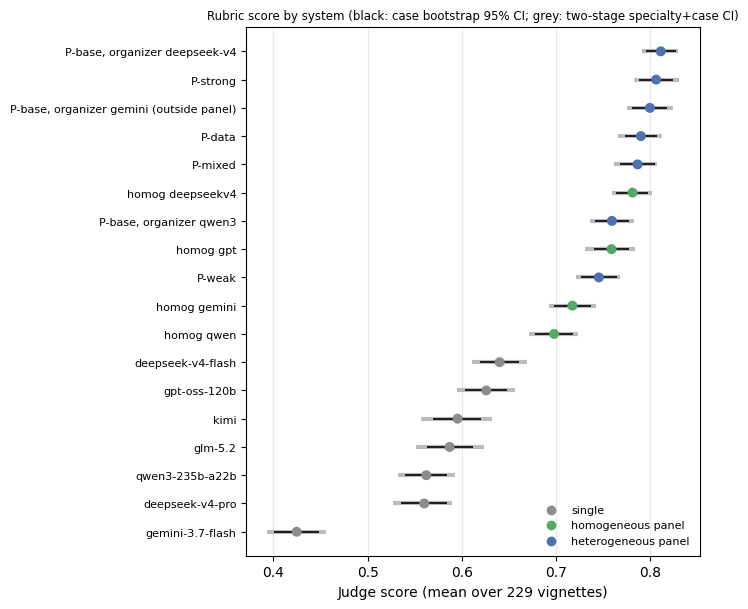

In [10]:
colors = {'single': '#8C8C8C', 'homogeneous panel': '#55A868', 'heterogeneous panel': '#4C72B0'}
t = tab.sort_values('judge_mean')
fig, ax = plt.subplots(figsize=(7.2, 6.2))
y = np.arange(len(t))
ax.hlines(y, t.ci_domain_lo, t.ci_domain_hi, color='#BBBBBB', lw=3)
ax.hlines(y, t.ci_case_lo, t.ci_case_hi, color='black', lw=1.2)
ax.scatter(t.judge_mean, y, c=[colors[k] for k in t.kind], s=38, zorder=3)
lab = []
for _, r in t.iterrows():
    nm = r.arm
    nm = nm.replace('P-base/org-ds', 'P-base, organizer deepseek-v4').replace('P-base/org-qwen', 'P-base, organizer qwen3').replace('P-base/org-gemini', 'P-base, organizer gemini (outside panel)')
    lab.append(nm)
ax.set_yticks(y)
ax.set_yticklabels(lab, fontsize=8)
ax.set_xlabel('Judge score (mean over 229 vignettes)')
for k, c in colors.items():
    ax.scatter([], [], c=c, label=k)
ax.legend(frameon=False, loc='lower right', fontsize=8)
ax.set_title('Rubric score by system (black: case bootstrap 95% CI; grey: two-stage specialty+case CI)', fontsize=8.5)
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(P.path_join(P.FIGURES, 'S_clinical_system_scores.png'), dpi=220)
